<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/03%20-%20Unsupervised%20Learning/solutions/03_unsupervised_solutions.ipynb)

# 03 — 无监督学习：课堂练习参考答案（Solutions）

本 Notebook 汇总了第三讲 `03a`、`03b`、`03c` 三个模块中全部 9 道课堂练习（`03a-1` 至 `03c-3`）的完整可运行参考代码与物理化学解析。每一节开头已包含对应模块的数据读取与前置特征计算，方便独立运行核对。

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "03 - Unsupervised Learning/solutions"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


---

# 03a — 降维与化学空间可视化（Dimensionality Reduction）练习答案

先运行 `03a` 的数据准备、17 个描述符的 PCA 投影与 2048 位 Morgan 指纹的前 50 维 PCA 预降维：

In [2]:
import os
os.environ["MKL_NUM_THREADS"] = "1"
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

RDLogger.DisableLog("rdApp.*")
plt.rcParams["figure.dpi"] = 110

DATA_PATHS = ["../data/solubility.csv", "data/solubility.csv", "solubility.csv"]
for p in DATA_PATHS:
    if os.path.exists(p):
        df = pd.read_csv(p)
        break

df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]

scaler = StandardScaler().fit(df[feature_cols])
X_scaled = scaler.transform(df[feature_cols])
pca = PCA().fit(X_scaled)
pcs = pca.transform(X_scaled)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]

fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = np.array([fp_gen.GetFingerprintAsNumPy(m) for m in df["mol"]], dtype=np.uint8)
pca_fp = PCA(n_components=50, random_state=42).fit(fps)
fp_50 = pca_fp.transform(fps)

def rough_class(mol, smiles):
    if "." in smiles:
        return "salt / mixture"
    if mol.GetRingInfo().NumRings() == 0:
        return "acyclic"
    if Descriptors.NumAromaticRings(mol) == 0:
        return "aliphatic rings only"
    if any(a.GetSymbol() in ("F", "Cl", "Br", "I") for a in mol.GetAtoms()):
        return "aromatic + halogen"
    return "aromatic"

df["class"] = [rough_class(m, s) for m, s in zip(df["mol"], df["SMILES"])]
print(f"成功准备 {len(df)} 个分子，PCA 与指纹计算完毕。")

成功准备 9480 个分子，PCA 与指纹计算完毕。


<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent.parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


### 练习 03a-1：检视 PC2 两端的极端分子

**题目回顾**：找出 `PC2` 最大（最亲油）的 5 个分子和最小（最极性）的 5 个分子，用 `Draw.MolsToGridImage` 画出它们的结构式（图例标出 `Name` 和 `logS`），观察它们是否符合“亲油 vs 极性”的解释。

PC2 Largest (Most Lipophilic)


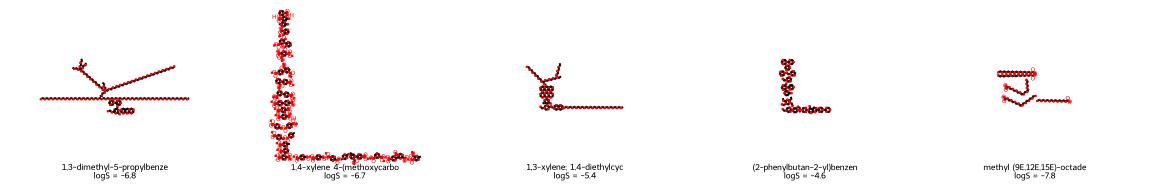

PC2 Smallest (Most Polar)


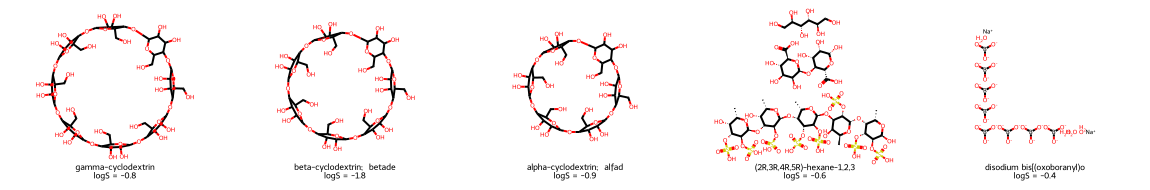

In [4]:
for title, rows in [("PC2 Largest (Most Lipophilic)", df.nlargest(5, "PC2")), ("PC2 Smallest (Most Polar)", df.nsmallest(5, "PC2"))]:
    print(title)
    display(Draw.MolsToGridImage(
        rows["mol"].tolist(),
        molsPerRow=5,
        subImgSize=(230, 190),
        legends=[f"{str(n)[:26]}\nlogS = {s:.1f}" for n, s in zip(rows["Name"], rows["Solubility"])],
    ))

**结果解析**：
- **PC2 最小（极度极性/亲水）的一端**：全是环糊精（$\alpha / \beta / \gamma$-cyclodextrin）、多羟基糖醇与多聚硼酸盐，分子表面密布羟基（`-OH`）和氧原子。值得注意的是，环糊精的分子量超过 1,000（因此 `PC1` 很大），但由于丰富的亲水羟基，水溶性依然很好（$\log S$ 在 $-0.4 \sim -1.8$ 之间）。这直观说明了 `PC2` 独立于分子大小（`PC1`），专门刻画“亲油 vs 极性”。
- **PC2 最大（极度疏水/亲油）的一端**：是一批包含超长碳链和多个苯环的巨型烃类或用 `.` 连接的多组分工业混合物（$\log S$ 在 $-4.6 \sim -7.8$ 之间），结构式甚至密得缩成一团。这也展示了**PCA 降维图在数据清洗中的重要实战价值**：散点图最边缘的极值点往往就是数据集中混入的聚合物片段、多组分混合物或录入异常条目，建模前非常值得把它们揪出来单独检查。

### 练习 03a-2：观察 `perplexity` 对 t-SNE 局部与全局颗粒度的影响

**题目回顾**：随机抽取 2,000 个分子的子集（`np.random.RandomState(0).choice(len(df), 2000, replace=False)`），分别用 `perplexity=5` 和 `perplexity=100` 运行 t-SNE，按 `class` 上色并排画图对比。

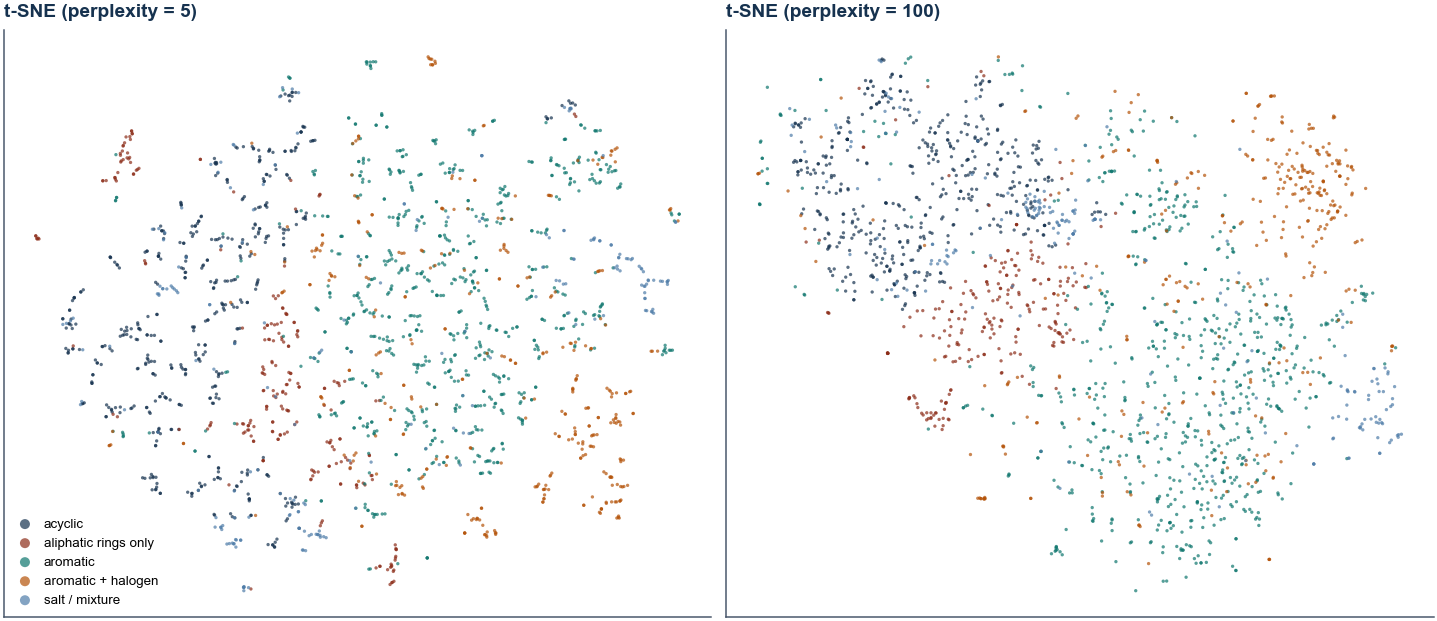

In [5]:
sub_idx = np.random.RandomState(0).choice(len(df), 2000, replace=False)
sub_df = df.iloc[sub_idx]
sub_50 = fp_50[sub_idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, perplexity in zip(axes, [5, 100]):
    emb = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=42).fit_transform(sub_50)
    for name in sorted(df["class"].unique()):
        mask = (sub_df["class"] == name).values
        ax.scatter(emb[mask, 0], emb[mask, 1], s=4, alpha=0.7, label=name)
    ax.set_title(f"t-SNE (perplexity = {perplexity})")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8)
plt.show()

**结果解析**：
- **`perplexity = 5`（高度关注极小局部）**：每个样本只看周围最近的几个邻居，整张图碎裂成上百个细小的孤岛（微小的同系物小团簇非常清晰，但宏观大类之间的相对位置几乎完全随机）。
- **`perplexity = 100`（兼顾较大范围邻域）**：每个样本考虑上百个邻居，细碎的小岛融合成平缓的大板块（无环分子、脂肪环、芳香分子、卤代芳烃各自连成大片区域）。
- 实践中没有唯一“正确”的 `perplexity`，通常从 `30` 开始，并对比多个值：**只有在多个不同 `perplexity` 下都稳定聚在一起的团簇，才是真实可靠的化学家族。**

### 练习 03a-3：将有机半导体分子并入指纹空间做 t-SNE 近邻分析

**题目回顾**：把 9 个有机半导体分子的 50 维指纹 PCA 特征拼接到 2,000 个分子子集后面，用 `perplexity=30` 一起运行 t-SNE，观察它们落在哪里，并打印 `3-hexylthiophene` 等分子的 5 个最近邻。

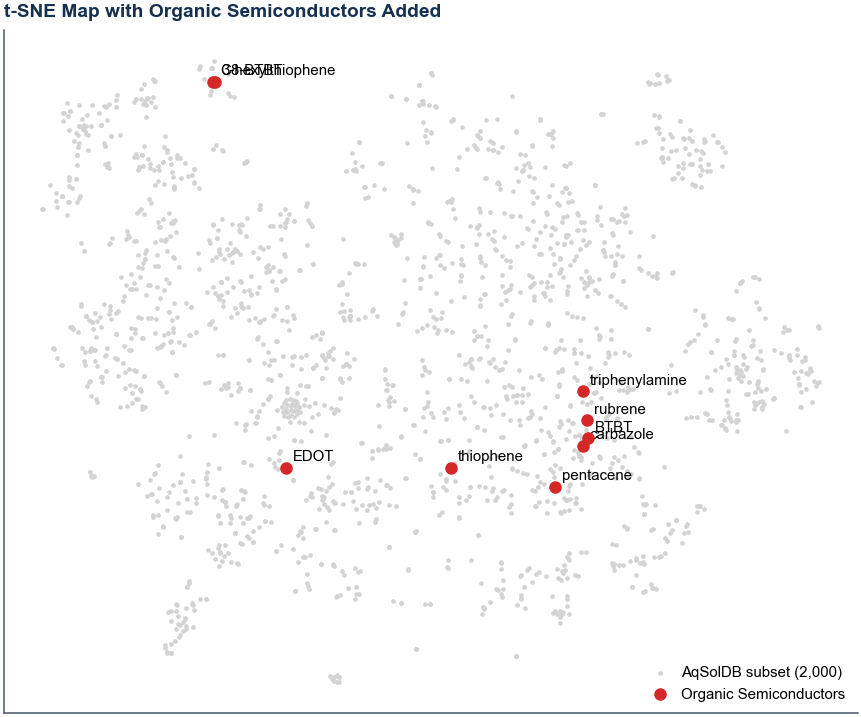


=== 3-hexylthiophene 在 t-SNE 图上的 Top-5 近邻 ===
  1-(4-Pentylcyclohexyl)-4-propylbenzene     | SMILES: CCCCCC1CCC(CC1)c2ccc(CCC)cc2
  3(2h)-isothiazolone, 2-octyl-              | SMILES: CCCCCCCCN1SC=CC1=O
  zinc bis(dinonylnaphthalenesulphonate)     | SMILES: [Zn++].CCCCCCCCCc1cc2ccccc2c(c1CCCCCCCCC)[S]([O-])(=O)=O.CCCCCCCCCc3cc4ccccc4c(c3CCCCCCCCC)[S]([O-])(=O)=O
  pentylbenzene                              | SMILES: CCCCCc1ccccc1
  octylbenzene                               | SMILES: CCCCCCCCc1ccccc1

=== pentacene 在 t-SNE 图上的 Top-5 近邻 ===
  2-ethylnaphthalene                         | SMILES: CCc1ccc2ccccc2c1
  phenanthridine                             | SMILES: c1ccc2c(c1)cnc3ccccc23
  2-methylnaphthalene                        | SMILES: Cc1ccc2ccccc2c1
  7h-dibenzo(c,g)carbazole                   | SMILES: [nH]1c2ccc3ccccc3c2c4c1ccc5ccccc45
  benz(a,j)aceanthrylene                     | SMILES: c1ccc2c(c1)ccc3c2cc4cccc5c6ccccc6c3c45

=== BTBT 在 t-SNE 图上的 Top-5 近邻 ===
  1H-1,3-ben

In [6]:
candidates = {
    "thiophene":        "c1ccsc1",
    "EDOT":             "C1COc2cscc2O1",
    "3-hexylthiophene": "CCCCCCc1ccsc1",
    "carbazole":        "c1ccc2c(c1)[nH]c1ccccc12",
    "triphenylamine":   "c1ccc(cc1)N(c1ccccc1)c1ccccc1",
    "pentacene":        "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1",
    "BTBT":             "c1ccc2c(c1)sc1c3ccccc3sc21",
    "C8-BTBT":          "CCCCCCCCc1ccc2c(c1)sc1c3ccc(CCCCCCCC)cc3sc21",
    "rubrene":          "c1ccc(cc1)-c1c2ccccc2c(-c2ccccc2)c2c(-c3ccccc3)c3ccccc3c(-c3ccccc3)c12",
}

osc_fps = np.array([fp_gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in candidates.values()], dtype=np.uint8)
both_50 = np.vstack([sub_50, pca_fp.transform(osc_fps)])   # 前 2000 行是 AqSolDB 子集，后 9 行是有机半导体
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(both_50)
emb_sub, emb_osc = emb[:2000], emb[2000:]

fig, ax = plt.subplots(figsize=(7.2, 6))
ax.scatter(emb_sub[:, 0], emb_sub[:, 1], s=4, color="lightgray", label="AqSolDB subset (2,000)")
ax.scatter(emb_osc[:, 0], emb_osc[:, 1], s=45, color="tab:red", zorder=5, label="Organic Semiconductors")
for name, (x, y) in zip(candidates, emb_osc):
    ax.annotate(name, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc="lower right")
ax.set_title("t-SNE Map with Organic Semiconductors Added")
plt.show()

names = list(candidates)
for target in ["3-hexylthiophene", "pentacene", "BTBT", "rubrene"]:
    point = emb_osc[names.index(target)]
    nearest = np.argsort(np.hypot(*(emb_sub - point).T))[:5]
    print(f"\n=== {target} 在 t-SNE 图上的 Top-5 近邻 ===")
    for _, row in sub_df.iloc[nearest].iterrows():
        print(f"  {str(row['Name'])[:42]:42s} | SMILES: {row['SMILES']}")

**结果解析**：
1. **刚性共轭母核聚在一起**：`pentacene`、`BTBT`、`rubrene`、`carbazole`、`triphenylamine` 都落在同一个多环芳烃/杂环芳烃区域，周围邻居分别是荧蒽、茚并芘、吩噻嗪、苯并噻唑与三苯基衍生物。
2. **长烷基侧链引发的“位置漂移”**：带长烷基链的 **`3-hexylthiophene` 和 `C8-BTBT` 几乎重叠在一起，远远偏离了未取代的 `thiophene` 和 `BTBT` 母核**！查看 `3-hexylthiophene` 的近邻可以发现，它们全是辛苯（octylbenzene）、辛基异噻唑酮等“一条长烷基链 + 一个小芳环”的分子。
3. **物理与表征启示**：在半径为 2 的 Morgan 指纹中，一条己基或辛基链产生的碳链局部碎片比特数甚至多于紧凑的共轭母核，因此指纹认为“`C8-BTBT` 离辛苯比离 `BTBT` 母核更近”。然而对于有机半导体的电荷传输（HOMO/LUMO 能级、重组能）而言，起决定作用的是共轭母核而非绝缘烷基链。这说明**当目标性质由特定功能骨架主导时，通用全分子指纹可能被庞大的柔性侧链喧宾夺主**。

---

# 03b — 聚类与严格数据划分（Clustering）练习答案

### 练习 03b-1：探究邻域半径 `eps` 对 DBSCAN 的决定性影响

**题目回顾**：在交错半月形数据 `make_moons` 上对比 `eps = 0.05, 0.15, 0.5` 时 DBSCAN 找出的簇数与噪声点数。

eps = 0.05: 识别出 30 个有效簇 | 253 个噪声点 (-1)
eps = 0.15: 识别出  2 个有效簇 |   1 个噪声点 (-1)
eps = 0.5 : 识别出  1 个有效簇 |   0 个噪声点 (-1)


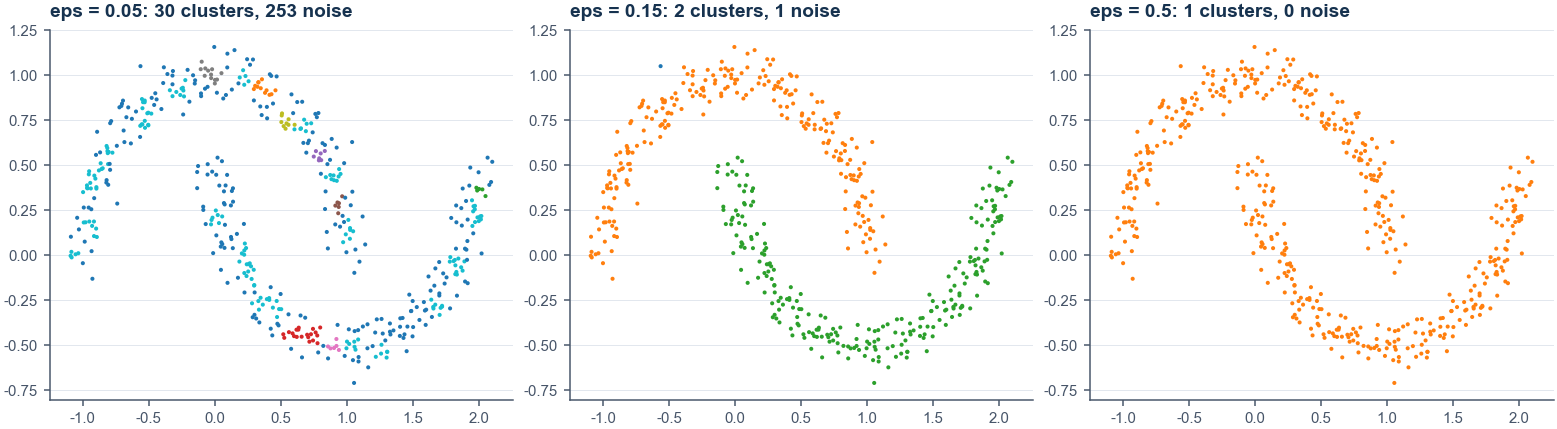

In [7]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=500, noise=0.07, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, eps in zip(axes, [0.05, 0.15, 0.5]):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_moons)
    n_clusters = len(set(labels) - {-1})
    n_noise = int((labels == -1).sum())
    ax.scatter(*X_moons.T, c=labels, s=6, cmap="tab10", vmin=-1, vmax=9)
    ax.set_title(f"eps = {eps}: {n_clusters} clusters, {n_noise} noise")
    print(f"eps = {eps:<4}: 识别出 {n_clusters:2d} 个有效簇 | {n_noise:3d} 个噪声点 (-1)")
plt.show()

**结果解析**：
- **`eps = 0.05`（半径过小）**：绝大多数点在 `0.05` 半径内凑不够 5 个邻居，导致原本连续的半月带碎裂成 30 个微型小簇，且超过一半的样本（253 个）被误判为孤立噪声点。
- **`eps = 0.15`（半径适中）**：恰好匹配同一流形内部相邻点的典型间距，小于两个半月之间的沟壑宽度，完美分离出 2 个簇（仅 1 个边缘噪声点）。
- **`eps = 0.5`（半径过大）**：邻域半径直接跨过了两个半月之间的空隙，把所有 500 个点连通吞并成了 1 个大簇。

### 练习 03b-2：盲测未知分子库的家族数量与化学身份

**题目回顾**：对 `unknown_clusters.csv` 中的 900 个分子计算 Morgan 指纹，扫描 $k=2 \dots 8$ 的 Inertia 与 Jaccard 轮廓系数，可视化每个簇的代表分子，并用调整兰德指数（`ARI`）与 `unknown_clusters_labels.csv` 核对。

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


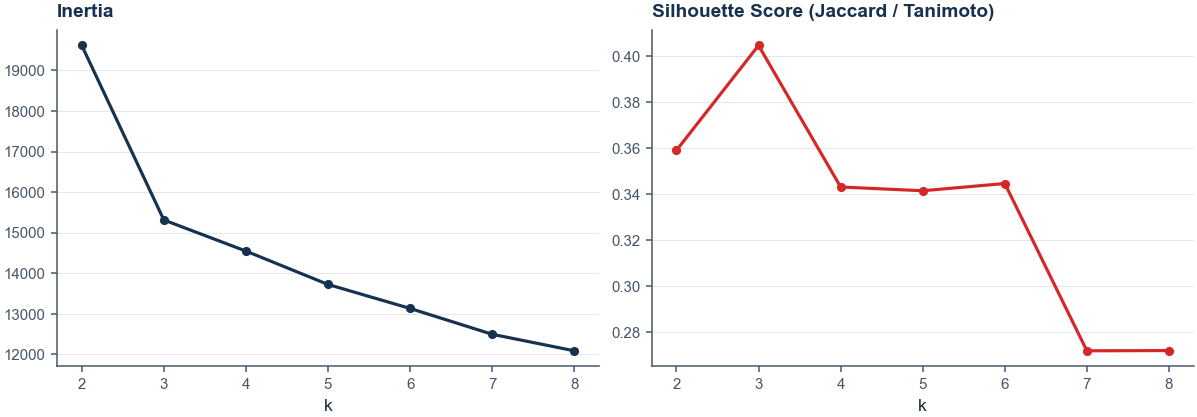

各 k 值对应的 Jaccard 轮廓系数: {2: 0.359, 3: 0.405, 4: 0.343, 5: 0.341, 6: 0.345, 7: 0.272, 8: 0.272}


In [8]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

UNK_PATHS = ["../data/unknown_clusters.csv", "data/unknown_clusters.csv"]
for p in UNK_PATHS:
    if os.path.exists(p):
        unknown = pd.read_csv(p)
        truth = pd.read_csv(p.replace("unknown_clusters.csv", "unknown_clusters_labels.csv"))["label"]
        break

unknown_mols = [Chem.MolFromSmiles(s) for s in unknown["smiles"]]
X_unknown = np.array([fp_gen.GetFingerprintAsNumPy(m) for m in unknown_mols], dtype=bool)

ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_unknown)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_unknown, km.labels_, metric="jaccard"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ks, inertias, "o-")
axes[0].set_xlabel("k")
axes[0].set_title("Inertia")

axes[1].plot(ks, silhouettes, "o-", color="tab:red")
axes[1].set_xlabel("k")
axes[1].set_title("Silhouette Score (Jaccard / Tanimoto)")
plt.show()

print("各 k 值对应的 Jaccard 轮廓系数:", dict(zip(ks, np.round(silhouettes, 3))))

簇 0（共 300 个分子）：


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


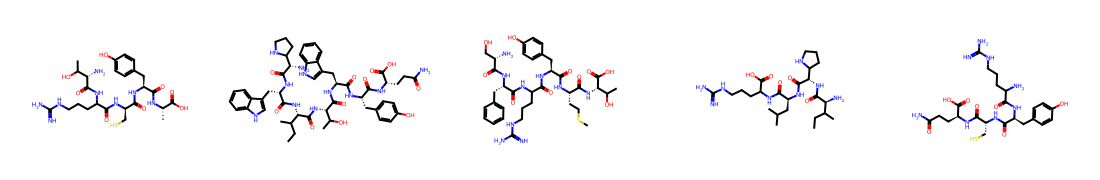

簇 1（共 300 个分子）：


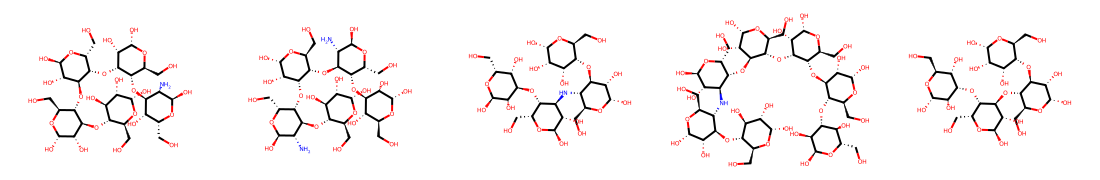

簇 2（共 300 个分子）：


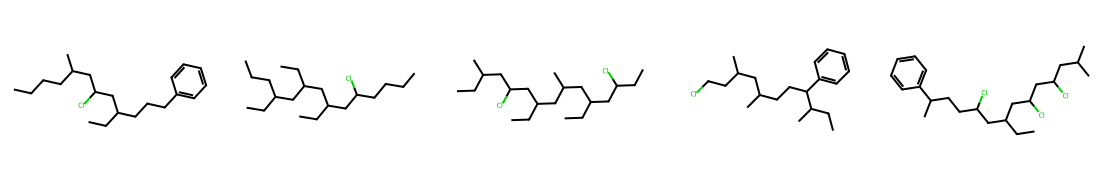

调整兰德指数 (Adjusted Rand Index, ARI) = 1.0


Predicted Cluster,0,1,2
True Class,,,
oligosaccharide,0,300,0
peptide,300,0,0
plastic,0,0,300


In [9]:
best_k = 3
labels_unknown = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(X_unknown)
rng = np.random.RandomState(0)

for c in range(best_k):
    members = np.where(labels_unknown == c)[0]
    shown = rng.choice(members, 5, replace=False)
    print(f"簇 {c}（共 {len(members)} 个分子）：")
    display(Draw.MolsToGridImage([unknown_mols[i] for i in shown], molsPerRow=5, subImgSize=(220, 180)))

print("调整兰德指数 (Adjusted Rand Index, ARI) =", round(adjusted_rand_score(truth, labels_unknown), 3))
pd.crosstab(truth, labels_unknown, rownames=["True Class"], colnames=["Predicted Cluster"])

**结果解析**：
- Inertia 肘部与 Jaccard 轮廓系数峰值（`0.409`）一致指向 **$k = 3$**。
- 检视各簇分子结构即可一眼认出三大生物/高分子家族：
  1. **多肽（Peptides，300 个）**：具有典型的酰胺键（`-CONH-`）主链与氨基酸侧链（如精氨酸胍基、酪氨酸酚羟基、色氨酸吲哚环）；
  2. **寡糖（Oligosaccharides，300 个）**：由多个吡喃糖环通过糖苷键串联而成，富含羟基；
  3. **合成塑料聚合物寡聚片段（Plastics，300 个）**：如聚氯乙烯（PVC）、聚苯乙烯（PS）等碳链重复单元。
- 与真实标签对比的调整兰德指数 **$\text{ARI} = 1.000$**，900 个分子无一分错！

### 练习 03b-3：聚类粒度（簇数 `n_clusters`）如何影响 Cluster Split 的难度？

**题目回顾**：对比 `n_clusters = 10, 50, 500` 以及随机 5 折划分下随机森林在 AqSolDB 上的交叉验证 RMSE。

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

X_aq = df[feature_cols].values
y_aq = df["Solubility"].values
fp_50_aq = PCA(n_components=50, random_state=0).fit_transform(fps)

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rand_scores = -cross_val_score(
    rf, X_aq, y_aq,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring="neg_root_mean_squared_error",
)
print(f"随机 5 折 (Random 5-Fold)      : 各折 RMSE {np.round(rand_scores, 2)} -> 平均 {rand_scores.mean():.2f} ± {rand_scores.std():.2f}")

for n_clusters in [500, 50, 10]:
    groups_n = KMeans(n_clusters=n_clusters, n_init=10, random_state=42).fit_predict(fp_50_aq)
    scores = -cross_val_score(
        rf, X_aq, y_aq,
        cv=list(GroupKFold(n_splits=5).split(X_aq, y_aq, groups_n)),
        scoring="neg_root_mean_squared_error",
    )
    print(f"按簇 5 折 ({n_clusters:3d} Clusters)       : 各折 RMSE {np.round(scores, 2)} -> 平均 {scores.mean():.2f} ± {scores.std():.2f}")

随机 5 折 (Random 5-Fold)      : 各折 RMSE [1.18 1.14 1.12 1.1  1.17] -> 平均 1.14 ± 0.03


按簇 5 折 (500 Clusters)       : 各折 RMSE [1.41 1.24 1.23 1.2  1.08] -> 平均 1.23 ± 0.11


按簇 5 折 ( 50 Clusters)       : 各折 RMSE [1.55 1.21 1.14 1.13 1.33] -> 平均 1.27 ± 0.16


按簇 5 折 ( 10 Clusters)       : 各折 RMSE [1.63 1.16 1.28 1.05 1.27] -> 平均 1.28 ± 0.20


**结果解析**：

| 交叉验证划分策略 | 5 折平均 RMSE | 折间标准差 |
|---|---|---|
| **Random 5-Fold（随机划分）** | `1.14` | `0.03` |
| **Cluster 5-Fold（500 个细粒度小簇）** | `1.23` | `0.09` |
| **Cluster 5-Fold（50 个中粒度簇）** | `1.27` | `0.15` |
| **Cluster 5-Fold（10 个粗粒度大簇）** | `1.28` | `0.20` |

- **为什么簇越少越难、簇越多越接近随机划分？**
  当只切成 10 个或 50 个大簇时，一整类化学家族（例如全部多氯联苯或全部长链表面活性剂）会被完整地放进同一个簇里，在某折测试时被**连根拔起**全部留作测试集，模型完全无法借助同系物内插，因此误差显著升高且折间波动变大。
- 反之，当切分成 500 个小簇时，原本属于同一大家族的分子被拆散到了十几个不同的小簇里；`GroupKFold` 把这些小簇分配到不同折时，一部分小簇进了训练集、另一部分进了测试集，测试集分子又能在训练集里找到“表亲”了。极端情况下，若簇数等于样本数 $N$（每个分子自己一簇），`GroupKFold` 就完全退化为随机划分。

---

# 03c — 科研实战案例：双核钯(I)催化剂发现（Pd Dimer Discovery）练习答案

先运行 `03c` 中的两轮数据读取与 1,000 次共识聚类函数：

In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

DATA_DIRS = ["../data", "data", "."]
for d in DATA_DIRS:
    if os.path.exists(os.path.join(d, "LKB_P.csv")):
        DATA_DIR = d
        break

ligands = pd.read_csv(os.path.join(DATA_DIR, "LKB_P.csv"), sep=";", index_col=0)
dimers  = pd.read_csv(os.path.join(DATA_DIR, "Dimer_LKB_P.csv"), sep=";", index_col=0)

POSITIVE = [16, 41, 54, 113]
NEGATIVE = [21]

drop_cols  = ["Type", "PC1", "PC2", "PC3", "PC4"]
drop_dimer = ["Type", "PC1", "PC2", "PC3", "PC4", "PC1'", "PC2'", "PC3'", "PC4'"]

X_lkb   = pd.DataFrame(StandardScaler().fit_transform(ligands.drop(columns=drop_cols)), index=ligands.index)
X_dimer = pd.DataFrame(MinMaxScaler().fit_transform(dimers.drop(columns=drop_dimer)), index=dimers.index)

def cluster_score(X, refs, k, n_runs=1000):
    counts = pd.Series(0, index=X.index)
    ref_pos = X.index.get_indexer(refs)
    for seed in range(n_runs):
        labels = KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X)
        ref_clusters = np.unique(labels[ref_pos])
        counts += np.isin(labels, ref_clusters)
    return counts / n_runs

score_round1 = cluster_score(X_lkb, POSITIVE, k=8, n_runs=1000)
score_round2 = cluster_score(X_dimer, POSITIVE, k=6, n_runs=1000)
new_candidates = [c for c in score_round2[score_round2 > 0.5].index if c not in POSITIVE]
print(f"第一轮 (Score > 0.75) 入选: {(score_round1 > 0.75).sum()} 个 | 第二轮 (Score > 0.5) 新候选: {len(new_candidates)} 个")

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

... (186 outputs left out)

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

第一轮 (Score > 0.75) 入选: 78 个 | 第二轮 (Score > 0.5) 新候选: 21 个


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

### 练习 03c-1：第一轮筛选阈值（Threshold）的敏感性分析

**题目回顾**：画出第一轮入选配体数随阈值（`0.05 ~ 0.95`）变化的曲线，并查看阈值取 `0.5, 0.75, 0.9, 0.99` 时的入选数量及 $\text{PCy}_3$ 是否混入。

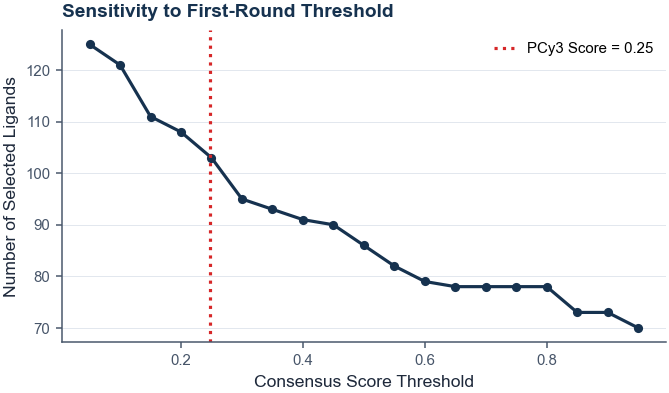

阈值 0.5 : 入选 86 个配体 | 反例 PCy3 入选？False
阈值 0.75: 入选 78 个配体 | 反例 PCy3 入选？False
阈值 0.9 : 入选 73 个配体 | 反例 PCy3 入选？False
阈值 0.99: 入选 54 个配体 | 反例 PCy3 入选？False


In [12]:
thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)
counts = [(score_round1 > t).sum() for t in thresholds]

plt.figure(figsize=(5.6, 3.3))
plt.plot(thresholds, counts, "o-")
plt.axvline(score_round1.loc[21], color="tab:red", ls=":", label=f"PCy3 Score = {score_round1.loc[21]:.2f}")
plt.xlabel("Consensus Score Threshold")
plt.ylabel("Number of Selected Ligands")
plt.title("Sensitivity to First-Round Threshold")
plt.legend()
plt.show()

for t in [0.5, 0.75, 0.9, 0.99]:
    print(f"阈值 {t:<4}: 入选 {(score_round1 > t).sum():2d} 个配体 | 反例 PCy3 入选？{score_round1.loc[21] > t}")

**结果解析**：
- 在 `0.50` 到 `0.90` 的宽广区间内，入选配体数从 86 个平缓变化到 73 个（因为绝大多数配体的 `Score` 呈双峰分布，集中在 `0` 或 `1` 两端，处于中间模糊地带的配体很少）。
- 反例 $\text{PCy}_3$ 的得分为 `0.247`，只有把阈值降到 `0.24` 以下才会被误选进来。论文选 `0.75` 既稳妥排除了反例，又保留了足够完整的核心近邻。

### 练习 03c-2：检验第二轮结果对簇数 $k$ 的稳健性

**题目回顾**：在第二轮中分别取 $k = 4, 6, 8, 10$（`n_runs=200`），统计 `Score > 0.5` 的新候选数，以及与基准 21 个新候选的重合度。

In [13]:
for k in [4, 6, 8, 10]:
    s = cluster_score(X_dimer, POSITIVE, k=k, n_runs=200)
    new_k = [c for c in s[s > 0.5].index if c not in POSITIVE]
    overlap = len(set(new_k) & set(new_candidates))
    print(f"k = {k:2d}: 选出 {len(new_k):2d} 个新候选 | 与基准 (k=6, 21个) 重合: {overlap:2d} 个")

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

... (59 outputs left out)

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

k = 10: 选出 12 个新候选 | 与基准 (k=6, 21个) 重合: 11 个


**结果解析**：
- 随着 $k$ 增大，每个簇的平均规模变小，入选的新候选总数自然减少（从 $k=4$ 的 34 个减少到 $k=10$ 的 12 个）。
- 但**核心候选名单具有极强的嵌套稳定性**：$k=6$ 和 $k=8$ 选出的 21 个候选完全一致；$k=4$ 选出的 34 个候选**100% 包含了**这 21 个核心候选；$k=10$ 选出的 12 个候选中也有 11 个属于这 21 个核心候选。

### 练习 03c-3：对比 `StandardScaler` 与 `MinMaxScaler` 对聚类结果的影响

**题目回顾**：把第二轮的特征缩放方式从 `MinMaxScaler` 换成 `StandardScaler`（`k=6, n_runs=200`），观察新候选名单的变化并解释原因。

In [14]:
X_dimer_std = pd.DataFrame(
    StandardScaler().fit_transform(dimers.drop(columns=drop_dimer)),
    index=dimers.index,
)
s_std = cluster_score(X_dimer_std, POSITIVE, k=6, n_runs=200)
new_std = [c for c in s_std[s_std > 0.5].index if c not in POSITIVE]

print(f"StandardScaler 选出: {len(new_std)} 个新候选 | 与 MinMaxScaler (21个) 重合: {len(set(new_std) & set(new_candidates))} 个")
print("仅在 StandardScaler 中多出的配体编号:", sorted(set(new_std) - set(new_candidates)))
print("仅在 MinMaxScaler 中出现的配体编号  :", sorted(set(new_candidates) - set(new_std)))

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

... (7 outputs left out)

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

StandardScaler 选出: 24 个新候选 | 与 MinMaxScaler (21个) 重合: 21 个
仅在 StandardScaler 中多出的配体编号: [40, 111, 112]
仅在 MinMaxScaler 中出现的配体编号  : []


c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

**结果解析**：
- 改用 `StandardScaler` 后共选出 24 个新候选：**原 `MinMaxScaler` 选出的 21 个候选配体全部包含在内（重合 21 个）**，仅在边界上额外多出了 3 个配体（编号 `40, 111, 112`）。
- **为什么缩放方式会影响 K-means？**
  K-means 依赖多维欧氏距离 $\sum_j (x_{ij} - \mu_{kj})^2$，每个特征列缩放后的方差大小直接决定了该特征在距离计算中的“权重”：
  - `MinMaxScaler` 强行把每个特征的最小值和最大值压到 `[0, 1]`。如果某列描述符存在一两个极端离群值（Outliers），其余 98% 的正常配体就会被挤压在 `[0, 0.1]` 这样极窄的区间里，导致该描述符在欧氏距离中的贡献被变相抹平；
  - `StandardScaler` 使每列的标准差都严格等于 `1`，不受单个极值点锁死上下界的影响。
- 在实际无监督筛选中，**换一种合理的特征缩放方式或微调 $k$ 值做交叉检验，确认核心候选名单不随预处理细节改变**，是非常推荐的科研习惯。